# Best Result Comparison by Bands (Online vs Replay)

这个 notebook 会：
1. 在 online 结果中找到 objective 最小的 trial；
2. 在 replay 结果中找到 objective 最小的 trial；
3. 画出两者的 S21/S11 曲线，并按三个 band 展示。

不调用仿真器，只读取已有 artifacts。


In [4]:
from __future__ import annotations

from pathlib import Path
import json
import os
import yaml
import sys

import numpy as np
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / 'experiments').exists() else NOTEBOOK_DIR.parent
os.chdir(REPO_ROOT)
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

from optimization.datasets import BCLFDataset

ONLINE_JSON_GLOB = 'bo_online_seed*.json'
REPLAY_JSON_GLOB = 'bo_replay_experiment_seed*.json'

ONLINE_DIR = REPO_ROOT / 'experiments' / 'bo_online'
REPLAY_DIR = REPO_ROOT / 'experiments' / 'bo_replay'

CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'

PASSBAND = (5.2e9, 5.9e9)
LOW_STOPBAND = (3.6e9, 4.8e9)
HIGH_STOPBAND = (6.5e9, 8.7e9)

online_jsons = sorted(ONLINE_DIR.glob(ONLINE_JSON_GLOB))
replay_jsons = sorted(REPLAY_DIR.glob(REPLAY_JSON_GLOB))

print('repo root:', REPO_ROOT)
print('online json files:', len(online_jsons))
for p in online_jsons[:5]:
    print(' -', p)
print('replay json files:', len(replay_jsons))
for p in replay_jsons[:5]:
    print(' -', p)

with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
freq_cfg = cfg['data']['freqs']
freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)


repo root: /home/zhanghf/projects/vector
online json files: 7
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed0.checkpoint.json
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed0.json
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed1.checkpoint.json
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed1.json
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed2.checkpoint.json
replay json files: 5
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed0.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed1.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed2.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed3.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed4.json


In [5]:
def db20(x: np.ndarray) -> np.ndarray:
    return 20.0 * np.log10(np.maximum(np.abs(x), 1e-15))


def parse_touchstone_s2p_ma(path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Parse 2-port Touchstone in MA format.
    Returns: freqs_hz, s_params complex array with shape (2,2,N)
    """
    unit_scale = {'hz':1.0, 'khz':1e3, 'mhz':1e6, 'ghz':1e9}
    freq_mul = None
    data = []

    with path.open('r', encoding='utf-8', errors='ignore') as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith('!'):
                continue
            if line.startswith('#'):
                parts = line[1:].strip().lower().split()
                # expected like: ghz s ma r 50
                if len(parts) >= 3:
                    freq_unit = parts[0]
                    param_type = parts[1]
                    data_fmt = parts[2]
                    if param_type != 's' or data_fmt != 'ma':
                        raise ValueError(f'Unsupported touchstone format {param_type} {data_fmt}; expected s ma')
                    freq_mul = unit_scale.get(freq_unit)
                    if freq_mul is None:
                        raise ValueError(f'Unsupported frequency unit: {freq_unit}')
                continue

            vals = line.split()
            if len(vals) < 9:
                continue
            nums = [float(v) for v in vals[:9]]
            data.append(nums)

    if freq_mul is None:
        raise ValueError(f'Missing # header in {path}')
    if not data:
        raise ValueError(f'No data rows in {path}')

    arr = np.asarray(data, dtype=float)
    f = arr[:,0] * freq_mul

    def ma_to_c(mag, ang_deg):
        return mag * np.exp(1j * np.deg2rad(ang_deg))

    s11 = ma_to_c(arr[:,1], arr[:,2])
    s21 = ma_to_c(arr[:,3], arr[:,4])
    s12 = ma_to_c(arr[:,5], arr[:,6])
    s22 = ma_to_c(arr[:,7], arr[:,8])

    s = np.zeros((2,2,len(f)), dtype=complex)
    s[0,0,:] = s11
    s[1,0,:] = s21
    s[0,1,:] = s12
    s[1,1,:] = s22

    return f, s


def pick_global_best_trial(json_paths: list[Path]) -> tuple[Path, dict]:
    best_file = None
    best_trial = None
    best_obj = np.inf

    for p in json_paths:
        payload = json.loads(p.read_text())
        for t in payload.get('trials', []):
            obj = float(t.get('objective', np.inf))
            if np.isfinite(obj) and obj < best_obj:
                best_obj = obj
                best_file = p
                best_trial = t

    if best_file is None or best_trial is None:
        raise RuntimeError('No valid trial found.')
    return best_file, best_trial


In [6]:
online_best_file, online_best_trial = pick_global_best_trial(online_jsons)
replay_best_file, replay_best_trial = pick_global_best_trial(replay_jsons)

print('Online best file:', online_best_file.name)
print('Online best objective:', online_best_trial['objective'])
print('Online best case_id:', online_best_trial.get('case_id'))

print('Replay best file:', replay_best_file.name)
print('Replay best objective:', replay_best_trial['objective'])
print('Replay best case_id:', replay_best_trial.get('case_id'))

# ---- load online best response from touchstone ----
sm = online_best_trial.get('simulation_metadata', {}) or {}
touchstone_rel = sm.get('touchstone_path')
if touchstone_rel is None:
    # fallback: try queue/done result json
    result_json_rel = sm.get('result_json_path')
    if result_json_rel is None:
        raise RuntimeError('Online best trial missing both touchstone_path and result_json_path')
    result_json_path = REPO_ROOT / result_json_rel
    result_payload = json.loads(result_json_path.read_text())
    touchstone_rel = result_payload.get('artifacts', {}).get('touchstone')

touchstone_path = REPO_ROOT / touchstone_rel
f_online, s_online = parse_touchstone_s2p_ma(touchstone_path)

# ---- load replay best response from dataset ----
dataset = BCLFDataset.from_pickle(DATASET_PATH, freqs=freqs)
idx = replay_best_trial.get('dataset_index')
if idx is None:
    geom = np.asarray(replay_best_trial.get('geometry'), dtype=float)
    f_replay, s_replay = dataset.get_response_by_geometry(geom)
else:
    idx = int(idx)
    f_replay = np.asarray(dataset.freqs, dtype=float)
    s_replay = np.asarray(dataset.S_pool[idx], dtype=complex)

# ensure replay shape is (2,2,N)
if s_replay.ndim == 3 and s_replay.shape[0] != 2:
    # expected already (2,2,N), keep as is if matches N at last axis
    pass

print('touchstone path:', touchstone_path)
print('online shape:', s_online.shape, 'replay shape:', s_replay.shape)


Online best file: bo_online_seed1.json
Online best objective: 1876.2249295114664
Online best case_id: bo_online_seed1_it0022
Replay best file: bo_replay_experiment_seed2.json
Replay best objective: 197.92117990178292
Replay best case_id: 350
touchstone path: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d78_L1_8d14_L2_7d87_W_1d02_W1_0d85_W2_0d93_S1_0d14_S2_0d6.s2p
online shape: (2, 2, 401) replay shape: (2, 2, 401)


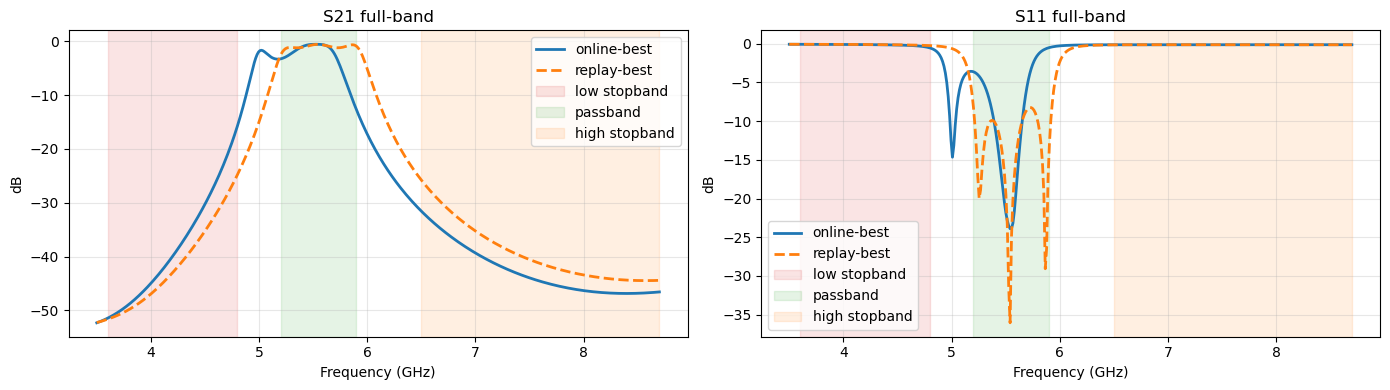

In [7]:
def band_mask(freq_hz: np.ndarray, band: tuple[float,float]) -> np.ndarray:
    return (freq_hz >= band[0]) & (freq_hz <= band[1])


def plot_full(f1, s1, f2, s2):
    f1g = f1 / 1e9
    f2g = f2 / 1e9

    s21_1 = db20(s1[1,0,:])
    s11_1 = db20(s1[0,0,:])
    s21_2 = db20(s2[1,0,:])
    s11_2 = db20(s2[0,0,:])

    fig, axes = plt.subplots(1,2, figsize=(14,4), sharex=False)

    for ax, y1, y2, ttl in [
        (axes[0], s21_1, s21_2, 'S21 full-band'),
        (axes[1], s11_1, s11_2, 'S11 full-band'),
    ]:
        ax.plot(f1g, y1, label='online-best', lw=2)
        ax.plot(f2g, y2, label='replay-best', lw=2, ls='--')
        ax.axvspan(LOW_STOPBAND[0]/1e9, LOW_STOPBAND[1]/1e9, alpha=0.12, color='tab:red', label='low stopband')
        ax.axvspan(PASSBAND[0]/1e9, PASSBAND[1]/1e9, alpha=0.12, color='tab:green', label='passband')
        ax.axvspan(HIGH_STOPBAND[0]/1e9, HIGH_STOPBAND[1]/1e9, alpha=0.12, color='tab:orange', label='high stopband')
        ax.set_title(ttl)
        ax.set_xlabel('Frequency (GHz)')
        ax.set_ylabel('dB')
        ax.grid(True, alpha=0.3)

    handles, labels = axes[0].get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    axes[0].legend(uniq.values(), uniq.keys(), loc='best')
    axes[1].legend(loc='best')
    plt.tight_layout()
    plt.show()


plot_full(f_online, s_online, f_replay, s_replay)


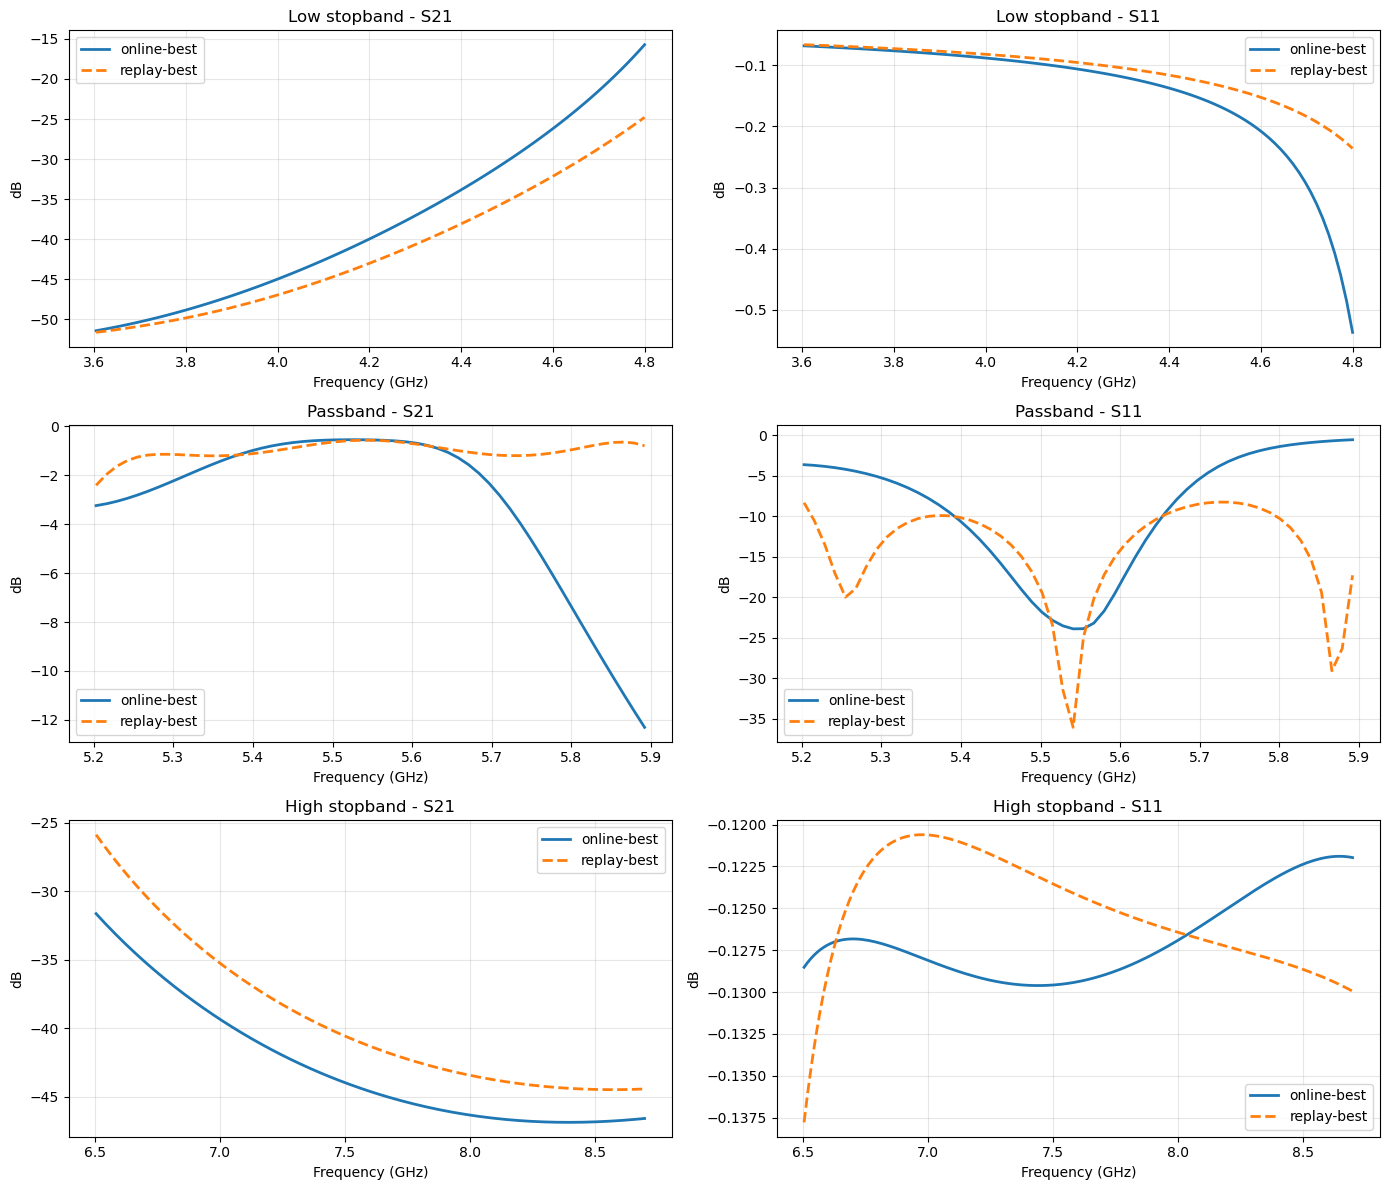

In [8]:
def plot_band_zoom(f1, s1, f2, s2):
    bands = [
        ('Low stopband', LOW_STOPBAND),
        ('Passband', PASSBAND),
        ('High stopband', HIGH_STOPBAND),
    ]

    fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=False)

    for i, (name, band) in enumerate(bands):
        m1 = band_mask(f1, band)
        m2 = band_mask(f2, band)

        f1g = f1[m1] / 1e9
        f2g = f2[m2] / 1e9

        # S21
        axes[i,0].plot(f1g, db20(s1[1,0,m1]), label='online-best', lw=2)
        axes[i,0].plot(f2g, db20(s2[1,0,m2]), label='replay-best', lw=2, ls='--')
        axes[i,0].set_title(f'{name} - S21')
        axes[i,0].set_xlabel('Frequency (GHz)')
        axes[i,0].set_ylabel('dB')
        axes[i,0].grid(True, alpha=0.3)
        axes[i,0].legend(loc='best')

        # S11
        axes[i,1].plot(f1g, db20(s1[0,0,m1]), label='online-best', lw=2)
        axes[i,1].plot(f2g, db20(s2[0,0,m2]), label='replay-best', lw=2, ls='--')
        axes[i,1].set_title(f'{name} - S11')
        axes[i,1].set_xlabel('Frequency (GHz)')
        axes[i,1].set_ylabel('dB')
        axes[i,1].grid(True, alpha=0.3)
        axes[i,1].legend(loc='best')

    plt.tight_layout()
    plt.show()


plot_band_zoom(f_online, s_online, f_replay, s_replay)


In [9]:
def summarize_band_metrics(freq_hz: np.ndarray, s: np.ndarray, prefix: str) -> dict:
    s21 = db20(s[1,0,:])
    s11 = db20(s[0,0,:])

    mp = band_mask(freq_hz, PASSBAND)
    ml = band_mask(freq_hz, LOW_STOPBAND)
    mh = band_mask(freq_hz, HIGH_STOPBAND)

    return {
        f'{prefix}_passband_s21_mean_db': float(np.mean(s21[mp])),
        f'{prefix}_passband_s21_min_db': float(np.min(s21[mp])),
        f'{prefix}_passband_s11_max_db': float(np.max(s11[mp])),
        f'{prefix}_low_stop_s21_max_db': float(np.max(s21[ml])),
        f'{prefix}_high_stop_s21_max_db': float(np.max(s21[mh])),
    }

m_online = summarize_band_metrics(f_online, s_online, 'online')
m_replay = summarize_band_metrics(f_replay, s_replay, 'replay')

rows = [{**m_online, **m_replay}]
import pandas as pd
display(pd.DataFrame(rows).T.rename(columns={0:'value'}))


,value
online_passband_s21_mean_db,-3.087258
online_passband_s21_min_db,-12.305657
online_passband_s11_max_db,-0.538930
online_low_stop_s21_max_db,-15.730322
online_high_stop_s21_max_db,-31.623107
replay_passband_s21_mean_db,-1.001471
replay_passband_s21_min_db,-2.406127
replay_passband_s11_max_db,-8.241221
replay_low_stop_s21_max_db,-24.789839
replay_high_stop_s21_max_db,-25.858661
